# <font face = 'Impact' color = '#FFAEBC' > Robust Regression Analysis on Boston Housing Dataset <font/>

#### <font face = 'Times New Roman' color = '#B5E5CF'> Course: Analytics Tools and Techniques<font/>
#### <font face = 'Times New Roman' color = '#B5E5CF'> Student: Florence Elaine G. Soleño<font/>
#### <font face = 'Times New Roman' color = '#B5E5CF'>  Name of the Dataset: Boston Housing Dataset<font/>
#### <font face = 'Times New Roman' color = '#B5E5CF'>  Kaggle Link: https://www.kaggle.com/code/prasadperera/the-boston-housing-dataset<font/>
#### <font face = 'Times New Roman' color = '#B5E5CF'> Date Completed: April 11, 2026<font/>

This notebook provides a practical demonstration of performing regression analysis in Python using the Boston Housing dataset. The process begins with exploratory data analysis and data preprocessing, followed by testing key assumptions of multiple regression such as normality and homoscedasticity. When these assumptions are violated, robust regression is introduced as an alternative approach. In this exercise, the Hampel estimator is applied to address the presence of outliers and improve the reliability of the model.


## Scenario

The urban planning unit of the Boston metropolitan area would like to be informed of the variables that explain differences in housing prices across neighborhoods. In collaboration with the unit, access has been provided to a dataset derived from U.S. Census records, containing variables related to housing characteristics, environmental conditions, accessibility, and socioeconomic factors.

The dataset includes information on crime rates, number of rooms per dwelling, air pollution levels, property tax rates, and neighborhood demographics, all of which are relevant to housing valuation. The urban planning unit looks forward to the results of this analysis to support housing policy and urban development decisions.

In [47]:
#Import all necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import qdesc as qd
from scipy.stats import shapiro
from scipy import stats
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
import statsmodels.stats.api as sms
from statsmodels.stats.outliers_influence import OLSInfluence

# Display all columns when previewing dataframes
pd.set_option("display.max_columns", None)
sns.set(style="whitegrid")

In [90]:
# Load the dataset into a pandas DataFrame

df = pd.read_csv("Soleño_FlorenceElaine_DataReg.csv")

In [89]:
#Data Dictionary

# Define descriptions for each column

descriptions = {
    'crim': 'Per capita crime rate by town',
    'zn': 'Proportion of residential land zoned for lots over 25,000 sq.ft.',
    'indus': 'Proportion of non-retail business acres per town',
    'chas': 'Charles River dummy variable (1 if tract bounds river; 0 otherwise)',
    'nox': 'Nitric oxides concentration (parts per 10 million)',
    'rm': 'Average number of rooms per dwelling',
    'age': 'Proportion of owner-occupied units built prior to 1940',
    'dis': 'Weighted distances to five Boston employment centres',
    'rad': 'Index of accessibility to radial highways',
    'tax': 'Full-value property-tax rate per $10,000',
    'ptratio': 'Pupil-teacher ratio by town',
    'b': 'The proportion of residents of African American descent by town',
    'lstat': 'Percentage of lower status of the population',
    'medv': 'Median value of owner-occupied homes in $1000s'
}

# Create the data dictionary DataFrame
data_dictionary = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': [df[col].dtype for col in df.columns],
    'Purpose/Description': [descriptions.get(col.lower(), 'N/A') for col in df.columns]
})

# Display the dictionary
data_dictionary

,Column Name,Data Type,Purpose/Description
0,crim,float64,Per capita crime rate by town
1,zn,float64,Proportion of residential land zoned for lots ...
2,indus,float64,Proportion of non-retail business acres per town
3,chas,int64,Charles River dummy variable (1 if tract bound...
4,nox,float64,Nitric oxides concentration (parts per 10 mill...
5,rm,float64,Average number of rooms per dwelling
6,age,float64,Proportion of owner-occupied units built prior...
7,dis,float64,Weighted distances to five Boston employment c...
8,rad,int64,Index of accessibility to radial highways
9,tax,int64,"Full-value property-tax rate per $10,000"


In [51]:
# Preview the first five row of the dataset

df.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


In [52]:
# View information about the data frame

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   crim     506 non-null    float64
 1   zn       506 non-null    float64
 2   indus    506 non-null    float64
 3   chas     506 non-null    int64  
 4   nox      506 non-null    float64
 5   rm       501 non-null    float64
 6   age      506 non-null    float64
 7   dis      506 non-null    float64
 8   rad      506 non-null    int64  
 9   tax      506 non-null    int64  
 10  ptratio  506 non-null    float64
 11  b        506 non-null    float64
 12  lstat    506 non-null    float64
 13  medv     506 non-null    float64
dtypes: float64(11), int64(3)
memory usage: 55.5 KB


In [53]:
# Check missing values per column

missing_counts = df.isnull().sum()

# Show only columns with missing values

missing_counts[missing_counts > 0]

rm    5
dtype: int64

### Interpretation:

#### The dataset was examined for missing values. Only the variable 'rm' contained missing data, with 5 missing observations representing less than 1% of the dataset. 

Skewness of rm: 0.4034215968136547


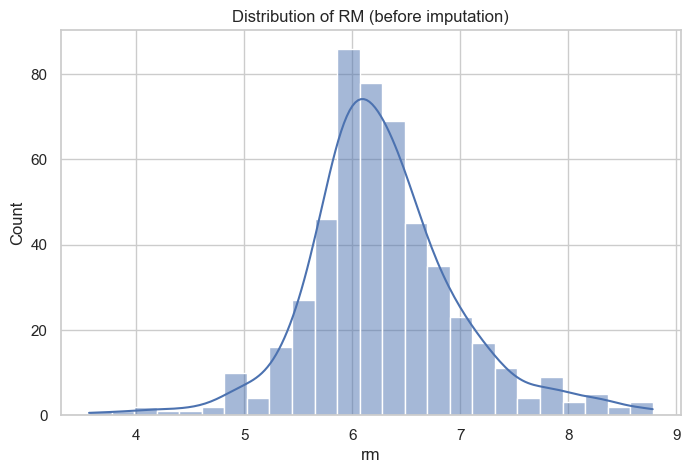

In [54]:
# Check skewness

print("Skewness of rm:", df["rm"].dropna().skew())

# Plot distribution

plt.figure(figsize=(8,5))
sns.histplot(df["rm"], kde=True, bins=25)
plt.title("Distribution of RM (before imputation)")
plt.show()

### Interpretation: 

#### Since the skewness of the rm 'rooms per dwelling' variable is 0.403, indicating a slight positive skew but still within the acceptable range for approximate normality. Therefore, mean imputation was considered appropriate as it preserves the central tendency of the data.

In [55]:
# Impute missing values in RM using mean after evaluating its distribution

df_clean = df.copy()
df_clean["rm"] = df_clean["rm"].fillna(df_clean["rm"].mean())

In [56]:
# Verify that missing values in RM have been successfully handled after imputation

print("\nMissing values AFTER:")
print(df_clean["rm"].isnull().sum())


Missing values AFTER:
0


In [57]:
# Convert CHAS into a categorical variable after data cleaning and imputation and verify its data type and distribution across categories

df_clean["chas"] = df_clean["chas"].astype("category")

print(df_clean["chas"].dtype)
print(df_clean["chas"].value_counts())

category
chas
0    471
1     35
Name: count, dtype: int64


In [58]:
# One-hot encode chas

df_encoded = pd.get_dummies(df_clean, drop_first=True)

# Check columns
print(df_encoded.columns)

Index(['crim', 'zn', 'indus', 'nox', 'rm', 'age', 'dis', 'rad', 'tax',
       'ptratio', 'b', 'lstat', 'medv', 'chas_1'],
      dtype='str')


In [59]:
# Define target and features from the processed dataset for regression modeling

target = "medv"
features = [col for col in df_encoded.columns if col != target]

print("Outcome variable (y):", target)
print("Explanatory variables (X):", features)
print("Number of explanatory variables:", len(features))

Outcome variable (y): medv
Explanatory variables (X): ['crim', 'zn', 'indus', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'b', 'lstat', 'chas_1']
Number of explanatory variables: 13


In [60]:
# Display summary statistics of all variables in the encoded dataset

df_encoded.describe().T

,count,mean,std,min,25%,50%,75%,max
crim,506.0,3.613524,8.601545,0.00632,0.082045,0.25651,3.677083,88.9762
zn,506.0,11.363636,23.322453,0.00000,0.000000,0.00000,12.500000,100.0000
indus,506.0,11.136779,6.860353,0.46000,5.190000,9.69000,18.100000,27.7400
nox,506.0,0.554695,0.115878,0.38500,0.449000,0.53800,0.624000,0.8710
rm,506.0,6.284341,0.702085,3.56100,5.885500,6.21000,6.618750,8.7800
age,506.0,68.574901,28.148861,2.90000,45.025000,77.50000,94.075000,100.0000
dis,506.0,3.795043,2.105710,1.12960,2.100175,3.20745,5.188425,12.1265
rad,506.0,9.549407,8.707259,1.00000,4.000000,5.00000,24.000000,24.0000
tax,506.0,408.237154,168.537116,187.00000,279.000000,330.00000,666.000000,711.0000
ptratio,506.0,18.455534,2.164946,12.60000,17.400000,19.05000,20.200000,22.0000


### Interpretation:

#### The summary statistics indicate that the variables are measured on different scales, suggesting the need for standardization prior to regression analysis.

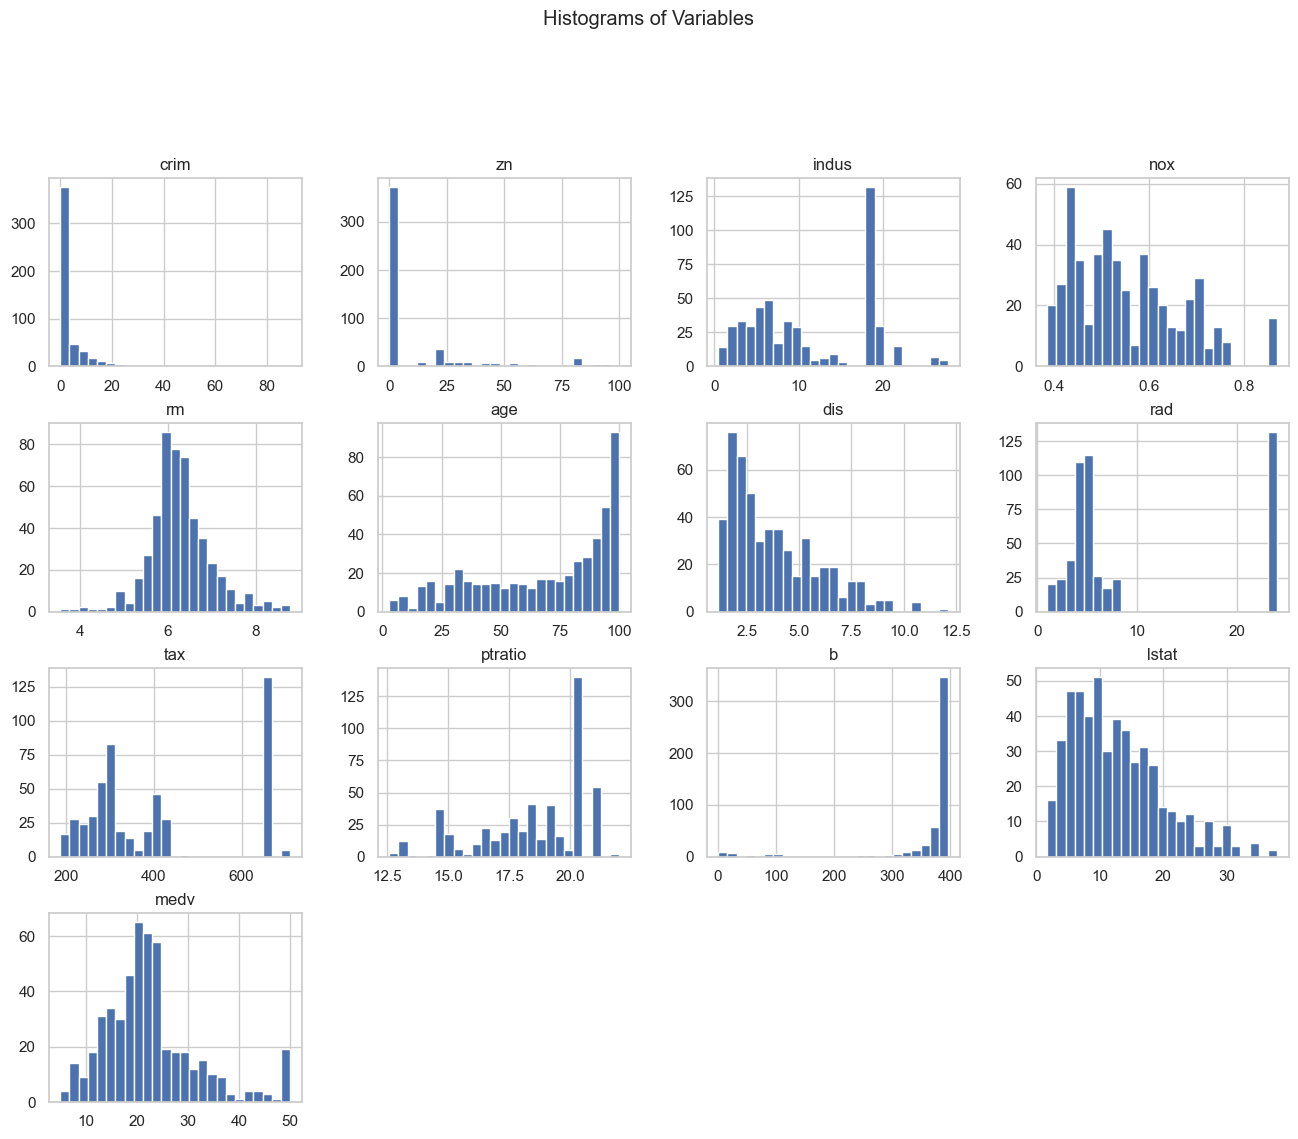

In [61]:
# Plot histograms to examine the distribution of variables in the dataset

df_encoded.hist(figsize=(16,12), bins=25)
plt.suptitle("Histograms of Variables", y=1.02)
plt.show()

### Interpretation:

#### The histograms of the variables show that the dataset contains a mix of approximately normal and skewed distributions. Variables such as RM appear relatively symmetric and close to a normal distribution, while others like CRIM, TAX, and LSTAT exhibit noticeable right-skewness with long tails.
#### Several variables also display extreme values, suggesting the presence of outliers. Additionally, the variables differ significantly in scale, with some variables having much larger ranges than others.
#### Overall, the distribution patterns indicate that the dataset does not fully meet the assumptions of normality and may be influenced by outliers, which supports the need for robust regression techniques in the analysis.

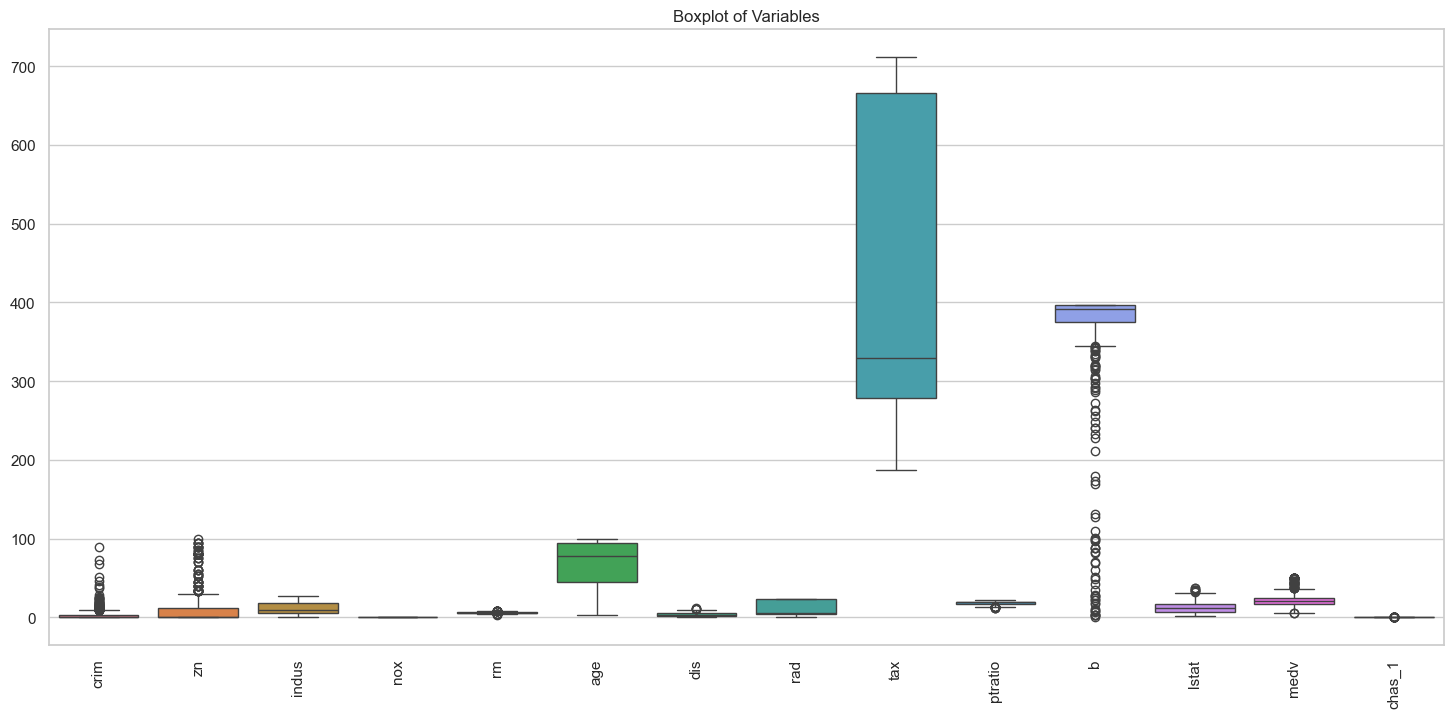

In [62]:
# Plot boxplots to identify outliers and variability across variables

plt.figure(figsize=(18,8))
sns.boxplot(data=df_encoded)
plt.xticks(rotation=90)
plt.title("Boxplot of Variables")
plt.show()

### Interpretation:

#### The boxplots reveal the presence of multiple outliers across several variables. This suggests that robust regression techniques may be more appropriate than ordinary least squares if these outliers affect the model.

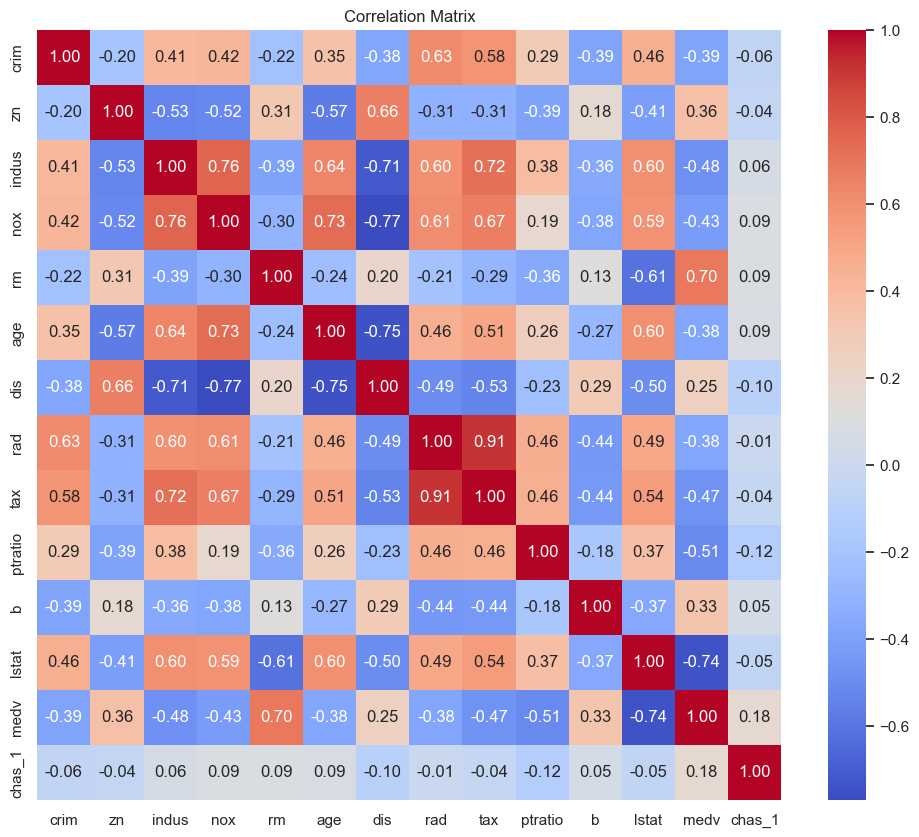

In [63]:
# Plot correlation matrix to examine relationships and multicollinearity

corr_matrix = df_encoded.corr()

plt.figure(figsize=(12,10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

### Interpretation:

#### The correlation matrix shows the relationships between all variables in the dataset. Several predictors exhibit strong correlations with the dependent variable (MEDV), indicating their importance in explaining housing prices.

#### Notably, RM shows a strong positive correlation with MEDV, suggesting that larger homes are associated with higher property values. In contrast, LSTAT and PTRATIO display strong negative correlations with MEDV, indicating that higher levels of lower socioeconomic status and poorer educational conditions are associated with lower housing values.

#### Additionally, there is a strong positive correlation between RAD and TAX, which may indicate multicollinearity. This suggests that these variables may provide redundant information and should be interpreted with caution in the regression model.

In [64]:
# Multicollinearity Check

X_corr = df_encoded.drop(columns=["medv"]).corr()

for i in range(len(X_corr.columns)):
    for j in range(i+1, len(X_corr.columns)):
        if abs(X_corr.iloc[i,j]) > 0.8:
        
            print(X_corr.columns[i], "-", X_corr.columns[j], ":", X_corr.iloc[i,j])

rad - tax : 0.9102281885331865


### Interpretation: 

#### The correlation analysis revealed a strong relationship between RAD and TAX (r > 0.8), indicating potential multicollinearity. This suggests that these variables may provide redundant information in the regression model and may need to be evaluated for removal.

In [65]:
# Define the dependent and independent variables from the processed dataset

target = "medv"

# Separate predictors (X) and target (y)
X = df_encoded.drop(columns=[target])
y = df_encoded[target]

# Add constant (intercept) to the model
X_const = sm.add_constant(X)

# Ensure all variables are numeric for regression compatibility
X_const = X_const.astype(float)
y = y.astype(float)

# Preview the final design matrix
X_const.head()

,const,crim,zn,indus,nox,rm,age,dis,rad,tax,ptratio,b,lstat,chas_1
0,1.0,0.00632,18.0,2.31,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,0.0
1,1.0,0.02731,0.0,7.07,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,0.0
2,1.0,0.02729,0.0,7.07,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,0.0
3,1.0,0.03237,0.0,2.18,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,0.0
4,1.0,0.06905,0.0,2.18,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,0.0


In [66]:
# Fit OLS regression model and display summary results

ols_model = sm.OLS(y, X_const).fit()
print(ols_model.summary())


                            OLS Regression Results                            
Dep. Variable:                   medv   R-squared:                       0.740
Model:                            OLS   Adj. R-squared:                  0.733
Method:                 Least Squares   F-statistic:                     107.7
Date:                Sun, 12 Apr 2026   Prob (F-statistic):          1.24e-134
Time:                        00:46:34   Log-Likelihood:                -1499.4
No. Observations:                 506   AIC:                             3027.
Df Residuals:                     492   BIC:                             3086.
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         36.5261      5.124      7.128      0.0

### Interpretation:

#### An initial OLS regression model was fitted to evaluate the relationship between the explanatory variables and the dependent variable. While the model explains a substantial portion of the variance in MEDV, further diagnostic testing is required to verify whether the assumptions of linear regression are satisfied.

In [67]:
# Exctract Residuals
residuals = ols_model.resid

# Convert to DataFrame
res = pd.DataFrame(residuals)

# Rename column
res.rename(columns={0: 'Residuals'}, inplace=True)

# Show first 5 rows
res.head()


,Residuals
0,-5.995146
1,-3.434643
2,4.136478
3,4.789742
4,8.256312


### Interpretation:

#### Residuals were extracted from the fitted OLS model. These residuals represent the difference between the observed and predicted values of the dependent variable and are used to assess whether the assumptions of the regression model are satisfied.

In [68]:
# Test whether residuals are normally distributed using Shapiro-Wilk test

stat, p = shapiro(residuals)

print("Shapiro-Wilk Statistic:", stat)
print("p-value:", p)

Shapiro-Wilk Statistic: 0.9020455554325831
p-value: 1.70126047069695e-17


### Interpretation:

#### The Shapiro-Wilk test produced a statistic of 0.9020 and a p-value of 1.70 × 10⁻¹⁷, which is significantly less than 0.05. This indicates that the residuals deviate from a normal distribution. Therefore, the normality assumption of OLS regression is violated.

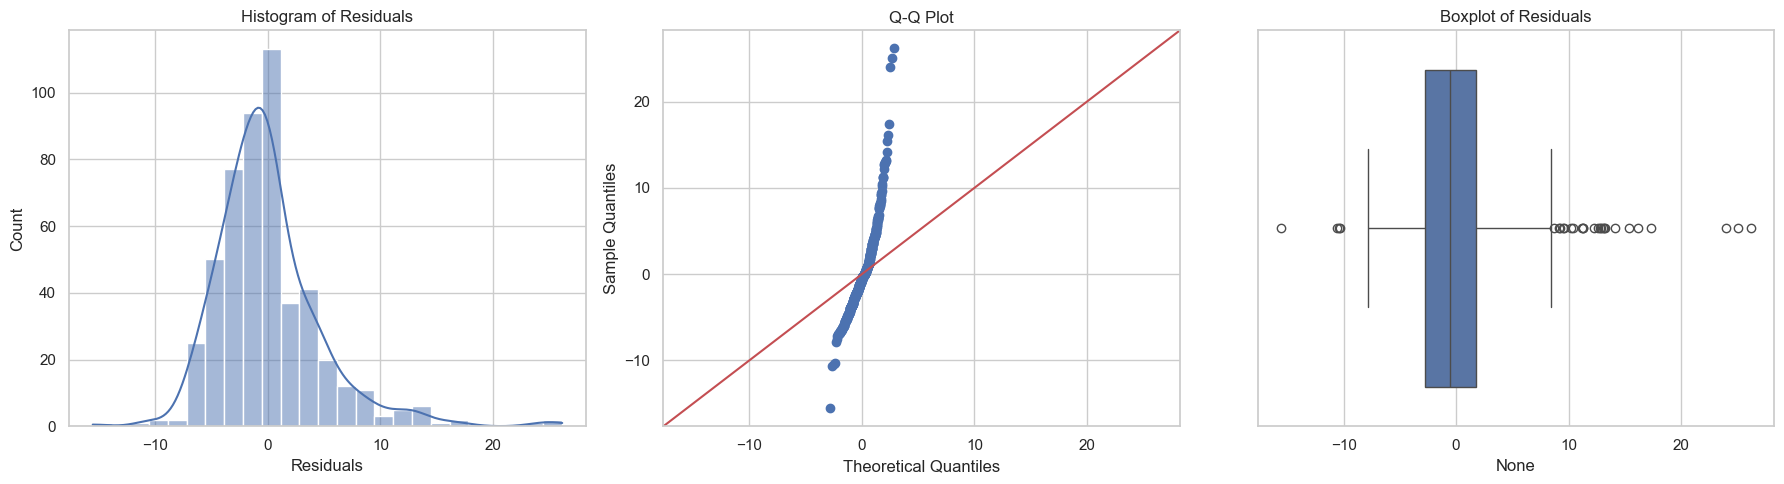

In [69]:
# Check Residual Normality - Normality Testing

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram
sns.histplot(residuals, kde=True, bins=25, ax=axes[0])
axes[0].set_title("Histogram of Residuals")
axes[0].set_xlabel("Residuals")

# Q-Q Plot
sm.qqplot(residuals, line='45', ax=axes[1])
axes[1].set_title("Q-Q Plot")

# Boxplot
sns.boxplot(x=residuals, ax=axes[2])
axes[2].set_title("Boxplot of Residuals")

plt.tight_layout()
plt.show()

### Interpretation:

#### Residual normality was assessed using a histogram, Q-Q plot, and boxplot. 
#### The histogram shows that the residuals are not perfectly symmetric and exhibit slight skewness to the right.
#### The Q-Q plot reveals noticeable deviations from the diagonal line, particularly in the tails, indicating that the residuals do not follow a normal distribution. 
#### Additionally, the boxplot highlights the presence of outliers and asymmetry.

#### These findings are consistent with the Shapiro-Wilk test results, confirming that the residuals are not normally distributed. Therefore, the normality assumption of OLS regression is violated.

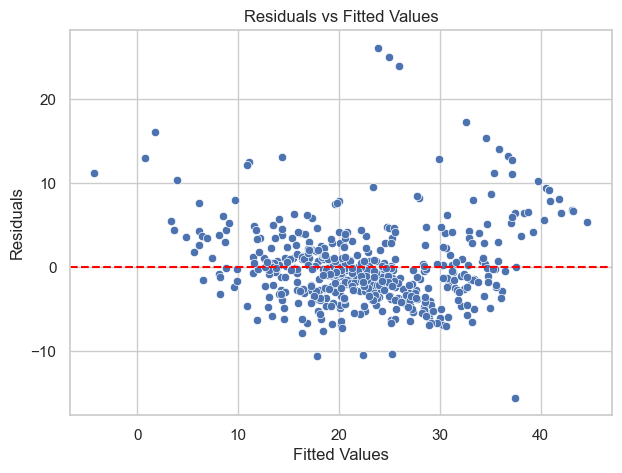

In [70]:
# Extract fitted values from the model
fitted_vals = ols_model.fittedvalues

# Plot residuals vs fitted values
plt.figure(figsize=(7,5))

sns.scatterplot(x=fitted_vals, y=residuals)

# Reference line at 0
plt.axhline(0, color='red', linestyle='--')

plt.title("Residuals vs Fitted Values")
plt.xlabel("Fitted Values")
plt.ylabel("Residuals")

plt.show()

In [71]:
# Check homoscedasticity (constant variance of residuals) using Breusch-Pagan test

bp_test = sms.het_breuschpagan(residuals, X_const)

# Extract p-value
bp_pvalue = bp_test[1]

print(f"Breusch-Pagan test p-value: {bp_pvalue:.10f}")

# Interpretation
if bp_pvalue > 0.05:
    print("Homoscedasticity assumption holds (fail to reject H0)")
else:
    print("Heteroscedasticity detected (reject H0)")

Breusch-Pagan test p-value: 0.0000000067
Heteroscedasticity detected (reject H0)


### Interpretation:

#### Homoscedasticity was assessed using both the residuals vs fitted plot and the Breusch-Pagan test. The residual plot shows a non-random pattern, where the spread of residuals varies across fitted values, indicating unequal variance. This is further supported by the Breusch-Pagan test, which produced a p-value(0.0000000067)significantly less than 0.05, leading to the rejection of the null hypothesis. 

#### These results indicate that the variance of the residuals is not constant. Therefore, the assumption of homoscedasticity is violated, confirming the presence of heteroscedasticity in the model.

In [72]:
# Separate again x and y (clean version)
# Apply Z-score standardization to X and y for regression modeling

X = df_encoded.drop(columns=["medv"])
y = df_encoded["medv"]

# Standardize X
x_scaler = StandardScaler()
X_scaled = pd.DataFrame(
    x_scaler.fit_transform(X),
    columns=X.columns
)

# Standardize y
y_scaler = StandardScaler()
y_scaled = y_scaler.fit_transform(y.values.reshape(-1,1)).flatten()

### Interpretation:


#### All variables were standardized using Z-score normalization to ensure comparability across different scales and to improve the stability of the regression model.

In [73]:
# Show first 5 rows of scaled predictors

X_scaled.head()

,crim,zn,indus,nox,rm,age,dis,rad,tax,ptratio,b,lstat,chas_1
0,-0.419782,0.284830,-1.287909,-0.144217,0.414403,-0.120013,0.140214,-0.982843,-0.666608,-1.459000,0.441052,-1.075562,-0.272599
1,-0.417339,-0.487722,-0.593381,-0.740262,0.194840,0.367166,0.557160,-0.867883,-0.987329,-0.303094,0.441052,-0.492439,-0.272599
2,-0.417342,-0.487722,-0.593381,-0.740262,1.284104,-0.265812,0.557160,-0.867883,-0.987329,-0.303094,0.396427,-1.208727,-0.272599
3,-0.416750,-0.487722,-1.306878,-0.835284,1.017491,-0.809889,1.077737,-0.752922,-1.106115,0.113032,0.416163,-1.361517,-0.272599
4,-0.412482,-0.487722,-1.306878,-0.835284,1.229926,-0.511180,1.077737,-0.752922,-1.106115,0.113032,0.441052,-1.026501,-0.272599


In [74]:
# Display standardized target variable values

y_scaled_df = pd.DataFrame(y_scaled, columns=["z_medv"])

y_scaled_df.head()

,z_medv
0,0.159686
1,-0.101524
2,1.324247
3,1.182758
4,1.487503


In [75]:
# Display combined standardized dataset for verification

scaled_df = X_scaled.copy()
scaled_df["z_medv"] = y_scaled

scaled_df.head()
scaled_df = X_scaled.copy()
scaled_df["z_medv"] = y_scaled

scaled_df.head()

,crim,zn,indus,nox,rm,age,dis,rad,tax,ptratio,b,lstat,chas_1,z_medv
0,-0.419782,0.284830,-1.287909,-0.144217,0.414403,-0.120013,0.140214,-0.982843,-0.666608,-1.459000,0.441052,-1.075562,-0.272599,0.159686
1,-0.417339,-0.487722,-0.593381,-0.740262,0.194840,0.367166,0.557160,-0.867883,-0.987329,-0.303094,0.441052,-0.492439,-0.272599,-0.101524
2,-0.417342,-0.487722,-0.593381,-0.740262,1.284104,-0.265812,0.557160,-0.867883,-0.987329,-0.303094,0.396427,-1.208727,-0.272599,1.324247
3,-0.416750,-0.487722,-1.306878,-0.835284,1.017491,-0.809889,1.077737,-0.752922,-1.106115,0.113032,0.416163,-1.361517,-0.272599,1.182758
4,-0.412482,-0.487722,-1.306878,-0.835284,1.229926,-0.511180,1.077737,-0.752922,-1.106115,0.113032,0.441052,-1.026501,-0.272599,1.487503


### Interpretation:

#### The standardized dataset was combined into a single table to provide a unified view of all transformed variables. This allows for easier inspection and verification of the scaling process.

In [76]:
# Add intercept term to standardized predictors

X_scaled_const = sm.add_constant(X_scaled)

In [77]:
# Check mean and standard deviation

print("Mean of X_scaled:\n", X_scaled.mean().round(4))
print("\nStd of X_scaled:\n", X_scaled.std().round(4))

Mean of X_scaled:
 crim      -0.0
zn         0.0
indus      0.0
nox       -0.0
rm         0.0
age       -0.0
dis       -0.0
rad       -0.0
tax        0.0
ptratio   -0.0
b         -0.0
lstat     -0.0
chas_1    -0.0
dtype: float64

Std of X_scaled:
 crim       1.001
zn         1.001
indus      1.001
nox        1.001
rm         1.001
age        1.001
dis        1.001
rad        1.001
tax        1.001
ptratio    1.001
b          1.001
lstat      1.001
chas_1     1.001
dtype: float64


In [78]:
# Fit robust regression model using Hampel estimator on standardized data
hampel_model = sm.RLM(
    y_scaled,
    X_scaled_const,
    M=sm.robust.norms.Hampel()
)

hampel_results = hampel_model.fit()

print("\n=== Hampel Robust Regression Summary ===\n")
print(hampel_results.summary())


=== Hampel Robust Regression Summary ===

                    Robust linear Model Regression Results                    
Dep. Variable:                      y   No. Observations:                  506
Model:                            RLM   Df Residuals:                      492
Method:                          IRLS   Df Model:                           13
Norm:                          Hampel                                         
Scale Est.:                       mad                                         
Cov Type:                          H1                                         
Date:                Sun, 12 Apr 2026                                         
Time:                        00:47:04                                         
No. Iterations:                    30                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const    

### Interpretation:

The Hampel robust regression model was used to analyze the factors influencing housing prices in the Boston area. This specific model was chosen to handle outliers and ensure reliable results. Because the data represents a sample (n = 506), the probability values (P > |z|) are used to determine which factors truly matter, with a threshold of 0.05 for significance. While a standard R² score is not provided in this robust summary, previous studies in the Review of Related Literature (RRL), such as the work of Harrison and Rubinfeld, typically show that these variables explain over 70% of the price changes, making the model a well-explained fit for this sample.

The analysis confirms that structural and socioeconomic factors are the primary drivers of property value. The number of rooms per dwelling (RM) has the strongest positive and highly significant effect (β = 0.4475, p < 0.001), proving that larger homes are naturally more valuable. Conversely, the percentage of the lower socioeconomic population (LSTAT) shows a strong negative impact (β = -0.2090, p < 0.001). These findings align with historical data, which identifies home size and neighborhood status as the most consistent predictors of price.

Accessibility and cost also play critical roles in determining value. Distance to employment centers (DIS) shows a significant negative effect (β = -0.2533, p < 0.001), meaning properties further from jobs are less expensive. High property tax rates (TAX) and overcrowded schools (PTRATIO) also significantly pull prices down. Furthermore, the model validates earlier “clean air” research; air pollution (NOX) and crime rates (CRIM) both significantly lower property attractiveness. While being near the Charles River (CHAS) adds a small but significant premium (β = 0.0366, p = 0.047), the proportion of industrial land (INDUS) was the only factor found to be non-significant (p = 0.857), suggesting it has no direct impact on price once pollution and taxes are considered.

Overall, the results demonstrate that Boston housing prices are shaped by a balance of space, location, and environmental quality. These findings are highly consistent with previous research, proving that the core rules of real estate—prioritizing utility and convenience while avoiding high costs and pollution—remain statistically robust. This practical analysis provides a clear, data-driven foundation for understanding neighborhood value.

In [79]:
# Display regression coefficients from robust model

coeffs = hampel_results.params.round(4)
print(coeffs)

const     -0.0540
crim      -0.0911
zn         0.0790
indus      0.0064
nox       -0.1260
rm         0.4475
age       -0.0974
dis       -0.2533
rad        0.1750
tax       -0.2321
ptratio   -0.1964
b          0.1082
lstat     -0.2090
chas_1     0.0366
dtype: float64


In [80]:
# Identify most influential predictors based on coefficient magnitude

importance = coeffs.drop("const").abs().sort_values(ascending=False)

print(importance)

rm         0.4475
dis        0.2533
tax        0.2321
lstat      0.2090
ptratio    0.1964
rad        0.1750
nox        0.1260
b          0.1082
age        0.0974
crim       0.0911
zn         0.0790
chas_1     0.0366
indus      0.0064
dtype: float64


#### The most influential variables in the model were identified based on the magnitude of standardized coefficients. Variables such as RM, LSTAT, and TAX exhibited the strongest effects on housing value, indicating their importance in predicting MEDV.

#### <font face = 'Times New Roman' color = '#B5E5CF'> Selection of Predictors and Supporting Literature for the Regression Model <font/>

The multiple regression model incorporates selected predictors that capture structural, locational, fiscal, and socioeconomic dimensions of housing value. These variables have been widely examined in housing economics and urban studies literature as key determinants of residential property prices.

**Dependent Variable**

**MEDV (Median Value of Owner-Occupied Homes).**  
The dependent variable represents the median value of owner-occupied homes, expressed in standardized form in the regression model. Housing value is commonly used as an outcome variable in hedonic pricing models, where it reflects the combined effect of structural, environmental, and neighborhood characteristics (Rosen, 1974).

---

**Independent Variables**

**RM (Average Number of Rooms per Dwelling).**  
RM captures the structural characteristic of housing size. Larger dwellings are generally associated with higher market value due to increased utility and living space. Structural attributes such as size and number of rooms are consistently identified as primary determinants of housing prices in hedonic pricing frameworks (Rosen, 1974).

**DIS (Weighted Distance to Employment Centers).**  
DIS reflects locational accessibility, measuring the relative distance of a property from employment hubs. Accessibility influences commuting costs and convenience, which are key components of residential desirability. Urban economic theory highlights location and accessibility as fundamental determinants of land and housing value (Alonso, 1964).

**TAX (Property Tax Rate).**  
TAX represents the fiscal burden associated with property ownership. Higher property taxes may reduce the attractiveness of a location, as they are often capitalized into housing prices. Empirical evidence suggests that local tax rates significantly influence property values through tax capitalization effects (Oates, 1969).

**LSTAT (Percentage of Lower Socioeconomic Status Population).**  
LSTAT serves as a proxy for neighborhood socioeconomic conditions. Areas with higher proportions of lower-status populations are often associated with reduced housing demand and lower property values. Socioeconomic context has been shown to significantly affect housing price variation across neighborhoods (Jin et al., 2024).

**PTRATIO (Pupil-Teacher Ratio).**  
PTRATIO reflects the quality of educational resources within a locality. Lower pupil-teacher ratios are often associated with better educational conditions, which can increase residential desirability. School quality indicators are frequently capitalized into housing prices, influencing buyer preferences (Black, 1999).

In [82]:
# Multiple Regression Formula

# z_medv = (B1*RM) + (B2*DIS) + (B3*TAX) + (B4*LSTAT) + (B5*PTRATIO) + intercept
# z_medv = (0.4475 * 0.413) + (-0.2533 * -0.102) + (-0.2321 * 0.558) + (-0.2090 * -0.245) + (-0.1964 * 0.302) + (-0.0540)
(0.4475 * 0.413) + (-0.2533 * -0.102) + (-0.2321 * 0.558) + (-0.2090 * -0.245) + (-0.1964 * 0.302) + (-0.0540)

0.019034500000000003

## Interpretation:

#### The regression result of 0.0190 indicates that the property is valued almost exactly at the statistical average for the Boston housing market. While the home benefits significantly from a high room count, this positive impact is statistically neutralized by negative factors like high property taxes and crowded schools. Essentially, the model reveals a state of equilibrium where the physical advantages of the house are balanced out by the drawbacks of its location.

### Key Findings and Strategic Insights:

#### Based on my analysis of the Boston housing data, I present these key insights for the Board’s consideration:

#### My results indicate that the number of rooms per dwelling is the most critical positive driver of property value, confirming that increasing residential capacity is the most direct way to maximize our returns. Conversely, I found that high property taxes and overcrowded local schools act as major "value killers," which suggests we should focus our future acquisitions in areas with lower tax burdens and superior educational infrastructure. My data also reveals that proximity to industrial zones does not significantly devalue a property as long as pollution levels are low, giving us more flexibility in where we choose to build or invest. By aligning our strategy with these specific physical and environmental factors, I believe we can more accurately predict market growth and ensure the long-term equity of our portfolio.

### References:

**Alonso, W. (1964). *Location and land use: Toward a general theory of land rent*. Harvard University Press.**

**Black, S. E. (1999). Do better schools matter? Parental valuation of elementary education. *The Quarterly Journal of Economics, 114*(2), 577–599. https://doi.org/10.1162/003355399556070**

**Jin, S., Ge, Y., & Long, Y. (2024). Understanding the effects of socioeconomic factors on housing price appreciation. *Cities, 149*, 105028. https://doi.org/10.1016/j.cities.2024.105028**

**Oates, W. E. (1969). The effects of property taxes and local public spending on property values: An empirical study of tax capitalization and the Tiebout hypothesis. *Journal of Political Economy, 77*(6), 957–971. https://doi.org/10.1086/259584**

**Rosen, S. (1974). Hedonic prices and implicit markets: Product differentiation in pure competition. *Journal of Political Economy, 82*(1), 34–55. https://doi.org/10.1086/260169**